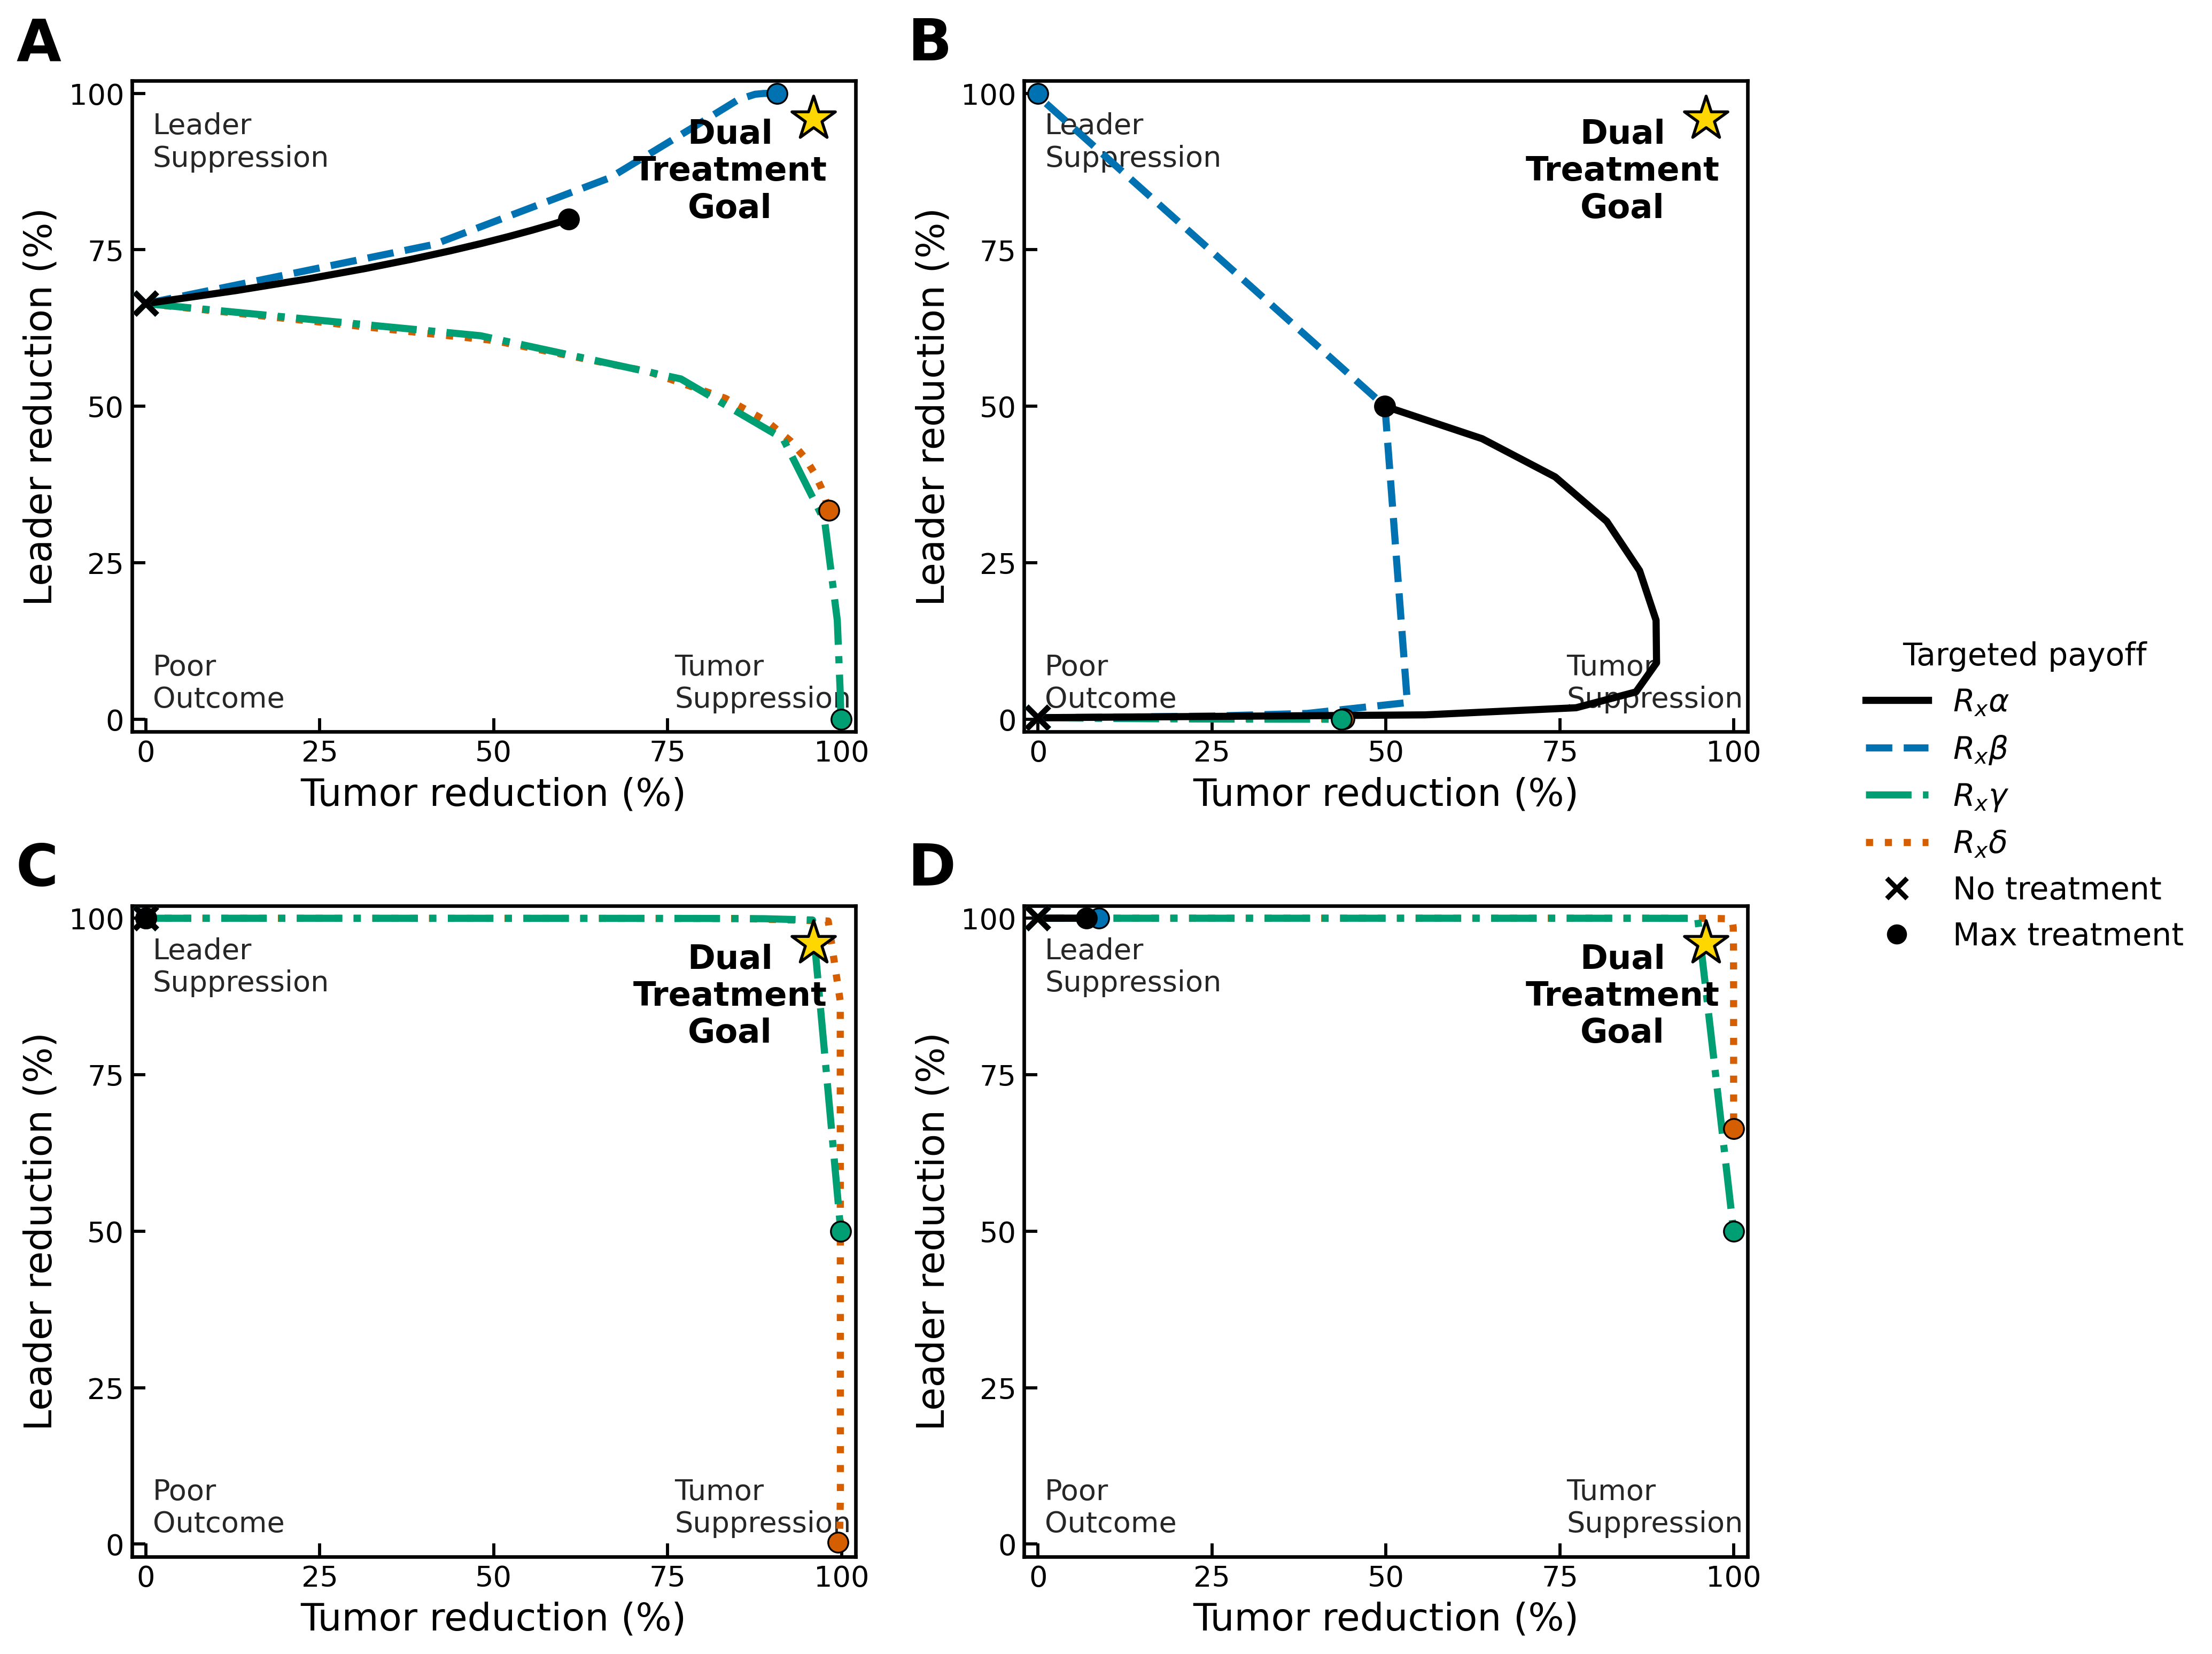

Saved: /content/fig5_dual_goal_clean.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from matplotlib.lines import Line2D
import os

# ============================================================
# Publication style
# ============================================================

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.labelsize": 17,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 14,
    "axes.linewidth": 1.6,
    "lines.linewidth": 3.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ============================================================
# Fitness functions
# ============================================================

def f_L(x, params, drug_cost, scenario, t):
    alpha = params["alpha"]
    beta = params["beta"]

    if scenario == "LF":
        return alpha*x + beta*(1-drug_cost)*(1-x)
    elif scenario == "LL":
        return alpha*(1-drug_cost)*x + beta*(1-x)
    else:
        return alpha*x + beta*(1-x)

def f_F(x, params, drug_cost, scenario, t):
    gamma = params["gamma"]
    delta = params["delta"]

    if scenario == "FF":
        return gamma*x + delta*(1-drug_cost)*(1-x)
    elif scenario == "FL":
        return gamma*(1-drug_cost)*x + delta*(1-x)
    else:
        return gamma*x + delta*(1-x)

def replicator_equations(y, t, params, drug_cost, scenario_L, scenario_F):
    N, x = y

    f_L_val = f_L(x, params, drug_cost, scenario_L, t)
    f_F_val = f_F(x, params, drug_cost, scenario_F, t)

    f_bar = x*f_L_val + (1-x)*f_F_val

    dN_dt = N*f_bar
    dx_dt = x*(1-x)*(f_L_val - f_F_val)

    return [dN_dt, dx_dt]

# ============================================================
# Parameters
# ============================================================

params_base = {
    "alpha": 0.4,
    "delta": 0.6
}

cases = [
    {"gamma": 0.8, "beta": 0.8},
    {"gamma": 0.2, "beta": 0.8},
    {"gamma": 0.2, "beta": 0.2},
    {"gamma": 0.8, "beta": 0.2}
]

labels = ["A", "B", "C", "D"]

scenarios = ["FF", "FL", "LF", "LL"]

colors = {
    "LL": "#000000",
    "LF": "#0072B2",
    "FL": "#009E73",
    "FF": "#D55E00",
}

linestyles = {
    "LL": "-",
    "LF": "--",
    "FL": "-.",
    "FF": ":",
}

scenario_labels_pretty = {
    "LL": r"$R_x\alpha$",
    "LF": r"$R_x\beta$",
    "FL": r"$R_x\gamma$",
    "FF": r"$R_x\delta$",
}

scenario_order = ["LL", "LF", "FL", "FF"]

t_eval = np.linspace(0, 30, 5000)
drug_costs_range = np.linspace(0, 1.0, 11)

# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13.5, 10.5),
    constrained_layout=False
)

axes = axes.flatten()

for idx, case in enumerate(cases):

    ax = axes[idx]

    # --------------------------------------------------------
    # Therapeutic target region
    # --------------------------------------------------------



    ax.scatter(
        96,
        96,
        marker="*",
        s=420,
        color="gold",
        edgecolor="black",
        linewidth=1.3,
        zorder=8
    )

    ax.text(
        84,
        96,
        "Dual\nTreatment\nGoal",
        fontsize=15,
        fontweight="bold",
        ha="center",
        va="top",
        zorder=9
    )

    ax.text(
        1,
        97,
        "Leader\nSuppression",
        fontsize=13,
        color="0.15",
        ha="left",
        va="top"
    )

    ax.text(
        76,
        1,
        "Tumor\nSuppression",
        fontsize=13,
        color="0.15",
        ha="left",
        va="bottom"
    )

    ax.text(
        1,
        1,
        "Poor\nOutcome",
        fontsize=13,
        color="0.15",
        ha="left",
        va="bottom"
    )

    # --------------------------------------------------------
    # Curves
    # --------------------------------------------------------

    for scenario in scenarios:

        leader_reduction_vals = []
        tumor_reduction_vals = []

        for d in drug_costs_range:

            y0 = [1e5, 0.5]
            params = {**params_base, **case}

            baseline = odeint(
                replicator_equations,
                y0,
                t_eval,
                args=(params, 0, "no_drug", "no_drug")
            )

            baseline_N = baseline[-1, 0]

            sol = odeint(
                replicator_equations,
                y0,
                t_eval,
                args=(params, d, scenario, scenario)
            )

            final_N, x_final = sol[-1]

            tumor_reduction = max(
                (baseline_N - final_N) / baseline_N * 100,
                0
            )

            leader_reduction = (1 - x_final) * 100

            tumor_reduction_vals.append(tumor_reduction)
            leader_reduction_vals.append(leader_reduction)

        ax.plot(
            tumor_reduction_vals,
            leader_reduction_vals,
            color=colors[scenario],
            linestyle=linestyles[scenario],
            linewidth=3.2,
            solid_capstyle="round",
            zorder=4
        )

        # no treatment marker
        ax.plot(
            tumor_reduction_vals[0],
            leader_reduction_vals[0],
            marker="x",
            color=colors[scenario],
            markersize=10,
            markeredgewidth=2.5,
            zorder=6
        )

        # strongest treatment marker
        ax.plot(
            tumor_reduction_vals[-1],
            leader_reduction_vals[-1],
            marker="o",
            color=colors[scenario],
            markersize=9,
            markerfacecolor=colors[scenario],
            markeredgecolor="black",
            markeredgewidth=0.8,
            zorder=7
        )

    # --------------------------------------------------------
    # Axis styling
    # --------------------------------------------------------

    ax.set_xlim(-2, 102)
    ax.set_ylim(-2, 102)

    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_yticks([0, 25, 50, 75, 100])

    ax.set_xlabel("Tumor reduction (%)")
    ax.set_ylabel("Leader reduction (%)")

    for side in ["top", "right", "bottom", "left"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.6)

    ax.grid(False)

    ax.text(
        -0.16,
        1.10,
        labels[idx],
        transform=ax.transAxes,
        fontsize=26,
        fontweight="bold",
        ha="left",
        va="top"
    )

# ============================================================
# Legend
# ============================================================

ordered_handles = [
    Line2D(
        [0], [0],
        color=colors[sc],
        lw=3.2,
        linestyle=linestyles[sc],
        label=scenario_labels_pretty[sc]
    )
    for sc in scenario_order
]

start_handle = Line2D(
    [0], [0],
    marker="x",
    color="black",
    linestyle="None",
    markersize=9,
    markeredgewidth=2.2,
    label="No treatment"
)

end_handle = Line2D(
    [0], [0],
    marker="o",
    color="black",
    markerfacecolor="black",
    linestyle="None",
    markersize=8,
    label="Max treatment"
)

fig.legend(
    handles=ordered_handles + [start_handle, end_handle],
    loc="center left",
    bbox_to_anchor=(0.86, 0.52),
    frameon=False,
    title="Targeted payoff"
)

plt.tight_layout(rect=[0, 0, 0.84, 1])

# ============================================================
# Save
# ============================================================

#fig.savefig("fig5_dual_goal_clean.pdf", bbox_inches="tight")
fig.savefig("fig5_dual_goal_clean.png", dpi=600, bbox_inches="tight")
#fig.savefig("fig5_dual_goal_clean.tiff", dpi=600, bbox_inches="tight")

plt.show()

#print("Saved:", os.path.abspath("fig5_dual_goal_clean.pdf"))
print("Saved:", os.path.abspath("fig5_dual_goal_clean.png"))
#print("Saved:", os.path.abspath("fig5_dual_goal_clean.tiff"))